In [1]:
import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

print("Updated PATH to include MPI")
print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

Updated PATH to include MPI
MPI location: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin
PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



In [2]:
import os
import os.path as op
import numpy as np
import matplotlib.pyplot as plt

import hnn_core
from hnn_core.externals.mne import tfr_array_morlet
from hnn_core.viz import plot_tfr_morlet
from hnn_core import MPIBackend, JoblibBackend, average_dipoles

import sys
sys.path.append('/users/kduecker/hnn-tuning/new_model_HNN')
sys.path.append('//users/kduecker/hnn-tuning/utils')
from general_plot_utils import assign_color

from hnn_core import duecker_ET_model, simulate_dipole
import matplotlib.pyplot as plt
import numpy as np
from hnn_core.externals.mne import tfr_array_morlet
pathfig = '/users/kduecker/hnn-tuning/new_model_HNN/figures/gamma'
os.makedirs(pathfig, exist_ok=True)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
n_procs=40

--No graphics will be displayed.


In [17]:
def plot_single_trial_sim(net, dpl):

    fig = plt.figure(constrained_layout=True, figsize=(20,3.5))

    gs = fig.add_gridspec(4,4, height_ratios=[.25, 0.25, 0.25, 0.25], hspace=0.3, wspace=.4)
    ax00 = fig.add_subplot(gs[0,0])
    ax10 = fig.add_subplot(gs[1:4,0])
    ax11 = fig.add_subplot(gs[0:2,1])
    ax21 = fig.add_subplot(gs[2:,1])
    ax3 = fig.add_subplot(gs[:,2])
    ax4 = fig.add_subplot(gs[:,3])

    # drives
    bins = np.arange(0, 1000, 5)
    spike_prox1 = np.array(net.cell_response.spike_times_by_type['prox_poiss'][0]).reshape(-1,1)

    ax00.hist(spike_prox1, bins=bins, color='r')
    ax00.set_xlim([0, 1000])
    ax00.set_xticklabels([])            
    # dipole
    ax10.plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1)
    ax10.set_ylabel('diple (nA·m)')
    ax10.set_xlim([0, 1000])
    ax10.spines['top'].set_visible(False)
    ax10.spines['right'].set_visible(False)
    ax10.set_xlabel('time (ms)')

    # dipole and raster
    I = np.array(net.cell_response.spike_gids[0]) < 135
    gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times).reshape(-1,)[I] 
    colors = [assign_color(net, gid) for gid in gids]

    ax11.plot(dpl[0].times, dpl[0].data['L2'], color='k', alpha=0.25)
    ax11.set_ylim([0, 0.01])
    ax11.set_xlim([0, 1000])
    ax11.set_ylabel('dipole (nA·m)')
    ax11.set_yticks([0.0, 0.005, 0.01])
    ax12 = ax11.twinx()

    ax12.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
    ax12.set_ylabel('L2/3 neurons')
    ax12.set_xticklabels([])
    ax12.invert_yaxis()
    ax12.set_yticks([0, 35, 135])


    I = (np.array(net.cell_response.spike_gids[0]) >= 135) & (np.array(net.cell_response.spike_gids[0]) < 270)
    gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times).reshape(-1,)[I] 
    colors = [assign_color(net, gid) for gid in gids]

    ax21.plot(dpl[0].times, dpl[0].data['L5'], color='k', alpha=0.25)
    ax21.set_xlim([0, 1000])
    ax21.set_ylim([-0.015, 0.03])
    ax21.set_yticks([-0.015, 0.0, 0.015, 0.03])
    ax22 = ax21.twinx()
    ax22.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
    ax22.set_ylabel('L5 neurons')
    ax22.invert_yaxis()
    ax22.set_yticks([135, 170, 270])
    ax21.set_xlabel('time (ms)')

    # TFR
    freqs = np.arange(20, 81, 1)

    tfr = np.zeros((len(dpl), len(freqs), len(dpl[0].times)))

    for i,d in enumerate(dpl):

        cur_tfr = tfr_array_morlet(d.data["agg"][None, None, :], d.sfreq, freqs, output='power')
        tfr[i] = cur_tfr.squeeze()

    tfr = tfr.mean(axis=0)
    
    im = ax3.pcolormesh(dpl[0].times, freqs, tfr, shading='auto', cmap='RdBu_r', vmin=0, vmax=np.round(tfr.max()+0.01,1))
    cb = plt.colorbar(im, pad=0.025)
    cb.set_ticks([0, np.round(tfr.max()/2,1), np.round(tfr.max(),1)])
    cb.set_label('power (nA·m)^2')
    ax3.set_xlabel('time (ms)')
    ax3.set_yticks([20, 40, 60, 80])
    ax3.set_ylabel('frequency (Hz)')

    # PSD
    dpl[0].plot_psd(ax=ax4, fmin=25, fmax=100, show=False, color='k')
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    ax4.set_xlabel('frequency (Hz)')

    return fig

def plot_multi_trial_sim(net, dpl):

    fig = plt.figure(constrained_layout=True, figsize=(20,3.5))

    gs = fig.add_gridspec(4,4, height_ratios=[.25, 0.25, 0.25, 0.25], hspace=0.3, wspace=.4)
    ax00 = fig.add_subplot(gs[0,0])
    ax10 = fig.add_subplot(gs[1:4,0])
    ax11 = fig.add_subplot(gs[0:2,1])
    ax21 = fig.add_subplot(gs[2:,1])
    ax3 = fig.add_subplot(gs[:,2])
    ax4 = fig.add_subplot(gs[:,3])

    # drives
    bins = np.arange(0, 1000, 5)
    spike_prox1 = np.array(net.cell_response.spike_times_by_type['prox_poiss'][0]).reshape(-1,1)

    ax00.hist(spike_prox1, bins=bins, color='r')
    ax00.set_xlim([0, 1000])
    ax00.set_xticklabels([])            
    # dipole
    ax10.plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1)
    ax10.set_ylabel('diple (nA·m)')
    ax10.set_xlim([0, 1000])
    ax10.spines['top'].set_visible(False)
    ax10.spines['right'].set_visible(False)
    ax10.set_xlabel('time (ms)')

    # dipole and raster
    I = np.array(net.cell_response.spike_gids[0]) < 135
    gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 
    colors = [assign_color(net, gid) for gid in gids]

    ax11.plot(dpl[0].times, dpl[0].data['L2'], color='k', alpha=0.25)
    ax11.set_ylim([0, 0.01])
    ax11.set_xlim([0, 1000])
    ax11.set_ylabel('dipole (nA·m)')
    ax11.set_yticks([0.0, 0.005, 0.01])
    ax12 = ax11.twinx()

    ax12.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
    ax12.set_ylabel('L2/3 neurons')
    ax12.set_xticklabels([])
    ax12.invert_yaxis()
    ax12.set_yticks([0, 35, 135])


    I = (np.array(net.cell_response.spike_gids[0]) >= 135) & (np.array(net.cell_response.spike_gids[0]) < 270)
    gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 
    colors = [assign_color(net, gid) for gid in gids]

    ax21.plot(dpl[0].times, dpl[0].data['L5'], color='k', alpha=0.25)
    ax21.set_xlim([0, 1000])
    ax21.set_ylim([-0.015, 0.03])
    ax21.set_yticks([-0.015, 0.0, 0.015, 0.03])
    ax22 = ax21.twinx()
    ax22.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
    ax22.set_ylabel('L5 neurons')
    ax22.invert_yaxis()
    ax22.set_yticks([135, 170, 270])
    ax21.set_xlabel('time (ms)')

    # TFR
    freqs = np.arange(20, 81, 1)

    cur_tfr = tfr_array_morlet(dpl[0].data["agg"][None, None, :], dpl[0].sfreq, freqs, output='power')
    tfr = cur_tfr.squeeze()
    
    im = ax3.pcolormesh(dpl[0].times, freqs, tfr, shading='auto', cmap='RdBu_r', vmin=0, vmax=np.round(tfr.max()+0.01,1))
    cb = plt.colorbar(im, pad=0.025)
    cb.set_ticks([0, np.round(tfr.max(),1)/2, np.round(tfr.max(),1)])
    cb.set_label('power (nA·m)^2')
    ax3.set_xlabel('time (ms)')
    ax3.set_yticks([20, 40, 60, 80])
    ax3.set_ylabel('frequency (Hz)')


    # average over trials

    tfr = np.zeros((len(dpl), len(freqs), len(dpl[0].times)))

    for i,d in enumerate(dpl):

        cur_tfr = tfr_array_morlet(d.data["agg"][None, None, :], d.sfreq, freqs, output='power')
        tfr[i] = cur_tfr.squeeze()

    tfr = tfr.mean(axis=0)
    
    im = ax4.pcolormesh(dpl[0].times, freqs, tfr, shading='auto', cmap='RdBu_r', vmin=0, vmax=np.round(tfr.max()+0.01,1))
    cb = plt.colorbar(im, pad=0.025)
    cb.set_ticks([0, np.round(tfr.max(),1)/2, np.round(tfr.max(),1)])
    cb.set_label('power (nA·m)^2')
    ax4.set_xlabel('time (ms)')
    ax4.set_yticks([20, 40, 60, 80])
    ax4.set_ylabel('frequency (Hz)')


    return fig

In [5]:
# sustained gamma 50 Hz
hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET.json')
params = hnn_core.read_params(params_fname)

In [80]:

net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.0045, 'L5_pyramidal': 0.0055}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 100.0, 'L5_pyramidal': 100.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=1)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

In [6]:
fig = plot_single_trial_sim(net, dpl)

fig.savefig(op.join(pathfig, 'gamma_ET_model_sustained50Hz.pdf'))

NameError: name 'net' is not defined

Joblib will run 40 trial(s) in parallel by distributing trials over 40 jobs.


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.


Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.soLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so

Building the NEURON modelLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so

Building the NEURON modelBuilding the NEURON model

Building the NEURON modelBuilding the NEURON model

Building the NEURON model
Loading custom mecha

--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.


Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.


Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.soLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so

Building the NEURON model
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.


Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mecha

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (40,) + inhomogeneous part.

/users/kduecker/.conda/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:96: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/users/kduecker/.conda/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


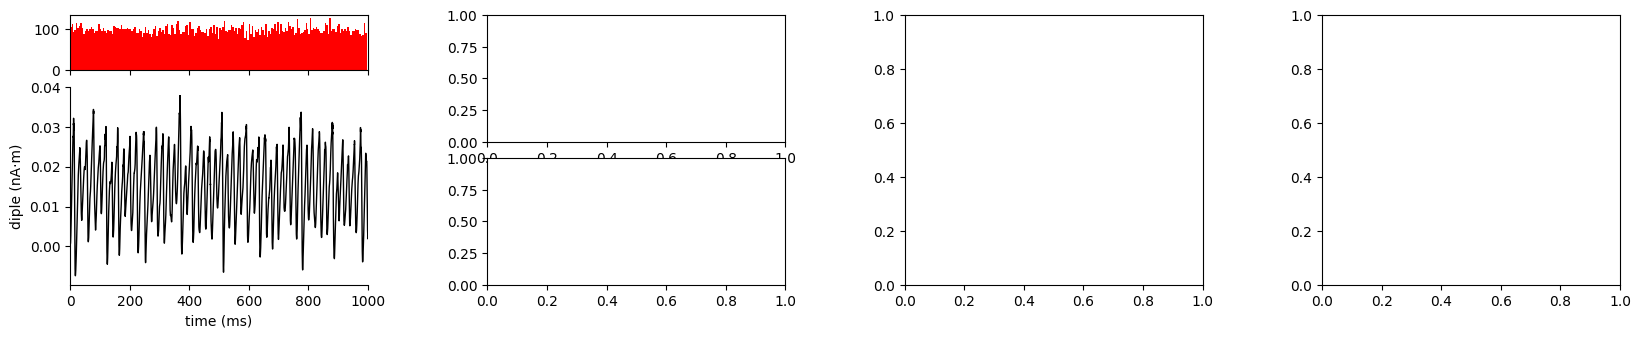

In [ ]:
net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.0045, 'L5_pyramidal': 0.0055}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 100.0, 'L5_pyramidal': 100.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

with JoblibBackend(n_jobs=n_procs):
    dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=40)



/tmp/ipykernel_2716224/630681820.py:2: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(op.join(pathfig, 'gamma_ET_model_sustainedbursty50Hz.pdf'))
/users/kduecker/.conda/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:96: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/users/kduecker/.conda/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


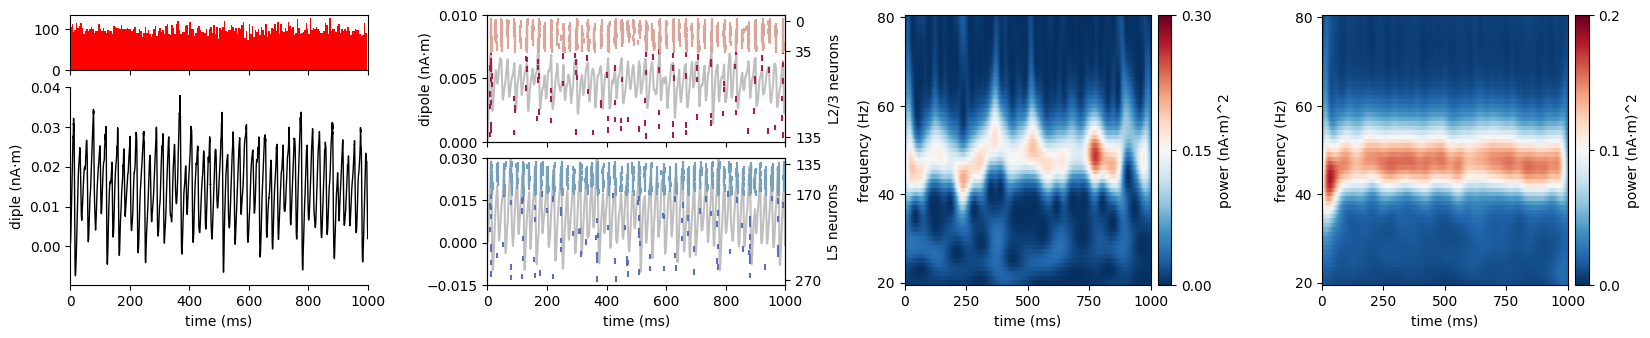

In [18]:
fig = plot_multi_trial_sim(net, dpl)
fig.savefig(op.join(pathfig, 'gamma_ET_model_sustainedbursty50Hz.pdf'))

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from 

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_51183/2348594667.py:19: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(op.join(pathfig, 'gamma_ET_model_strong_sustained40Hz.pdf'))
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


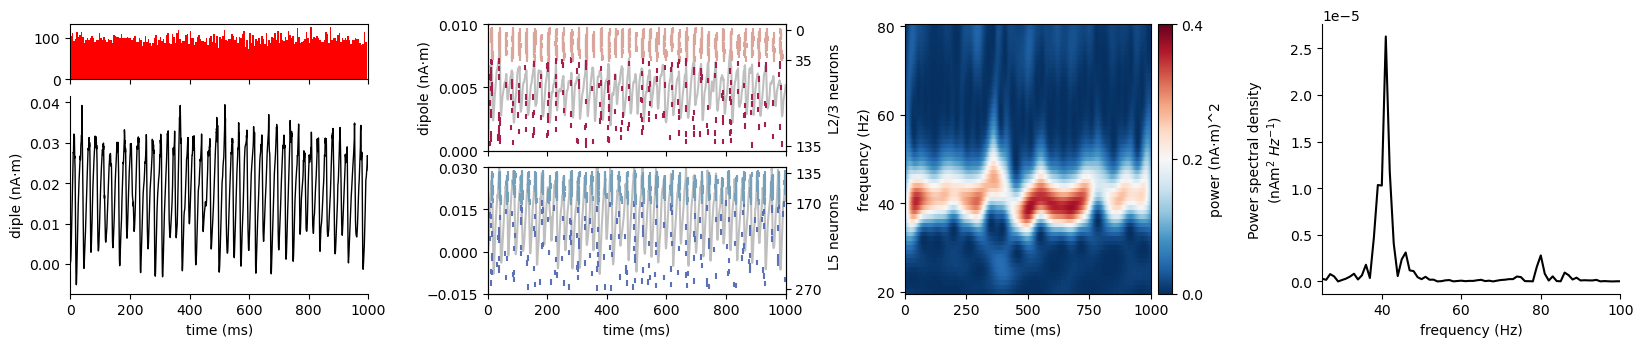

In [79]:
# strong gamma 40 Hz with 80 Hz harmonic

hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET_sustained40Hz.json')
params = hnn_core.read_params(params_fname)
net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.0045, 'L5_pyramidal': 0.0055}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 100.0, 'L5_pyramidal': 100.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=1)

fig = plot_single_trial_sim(net, dpl)

fig.savefig(op.join(pathfig, 'gamma_ET_model_strong_sustained40Hz.pdf'))

In [11]:
hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET_bursty.json')
params = hnn_core.read_params(params_fname)

net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.0035, 'L5_pyramidal': 0.0055}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 100.0, 'L5_pyramidal': 100.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays)

with JoblibBackend(n_jobs=40):
    dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=40)

Joblib will run 40 trial(s) in parallel by distributing trials over 40 jobs.


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.


Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mecha

--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.


Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.


Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mecha

/tmp/ipykernel_1919670/248201057.py:75: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.pdf'))
/users/kduecker/.conda/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:96: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/users/kduecker/.conda/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


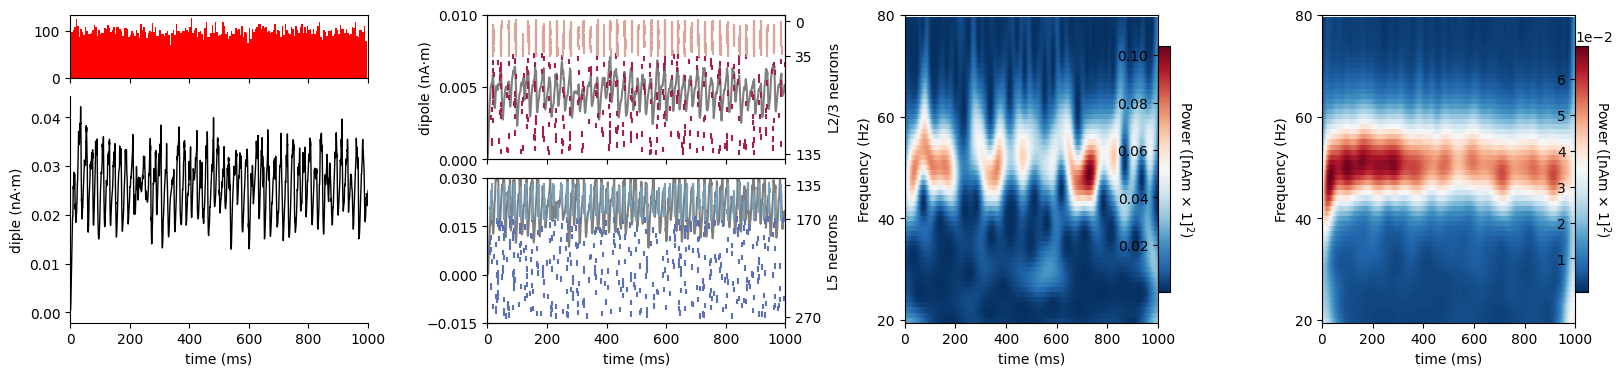

In [ ]:
fig = plot_multi_trial_sim(net, dpl)

fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.pdf'))

In [18]:
# Exploratory: duecker ET model in response to strong proximal followed by weak poissoin

hnn_core_root = op.dirname(hnn_core.__file__)

net = duecker_ET_model()
weights_ampa = {'L2_basket': 0.0, 'L2_pyramidal': 0.0035, 'L5_basket': 0.0, 'L5_pyramidal': 0.0035}
synaptic_delays = {'L2_basket':0.1, 'L2_pyramidal': 0.1, 'L5_basket': .1, 'L5_pyramidal': .1}
rate_constant = {'L2_basket': 200, 'L2_pyramidal': 200.0, 'L5_basket': 200, 'L5_pyramidal': 200.0}

net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=1)

fig = plot_single_trial_sim(net, dpl)


/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:909: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 1 trial(s) sequentially by distributing network neurons over 64 processes.
numprocs=64
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.soLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so

Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/li

/users/kduecker/.conda/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:96: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/users/kduecker/.conda/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


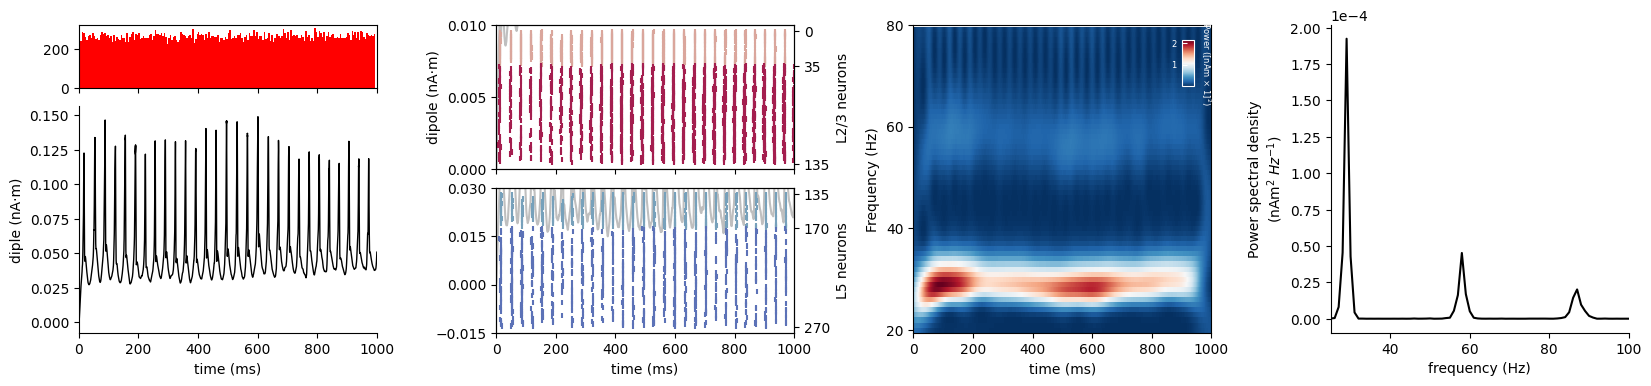